In [58]:
import os

test_path = "/kaggle/input/datasets/kaviyam23adr085/lekumiaaa/C-NMC_Leukemia/testing_data"

for root, dirs, files in os.walk(test_path):
    print(root)

/kaggle/input/datasets/kaviyam23adr085/lekumiaaa/C-NMC_Leukemia/testing_data
/kaggle/input/datasets/kaviyam23adr085/lekumiaaa/C-NMC_Leukemia/testing_data/C-NMC_test_final_phase_data


In [59]:
# =============================================================================
# NOTEBOOK 1
# CELL 1 : IMPORT LIBRARIES
# =============================================================================

import os
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import cv2

from glob import glob

from sklearn.model_selection import train_test_split

import albumentations as A

from albumentations.pytorch import ToTensorV2

import torch
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore")

print("="*80)
print("NOTEBOOK 1 : DATA PREPROCESSING")
print("="*80)

NOTEBOOK 1 : DATA PREPROCESSING


In [60]:
# =============================================================================
# CELL 2 : RANDOM SEED
# =============================================================================

SEED = 42

random.seed(SEED)

np.random.seed(SEED)

torch.manual_seed(SEED)

torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True

torch.backends.cudnn.benchmark = False

device = torch.device(

    "cuda"

    if torch.cuda.is_available()

    else

    "cpu"

)

print("Device :", device)

Device : cuda


In [61]:
# =============================================================================
# CELL 3 : DATASET PATH
# =============================================================================

DATASET_PATH = "/kaggle/input/datasets/kaviyam23adr085/lekumiaaa/C-NMC_Leukemia"

TRAIN_PATH = os.path.join(

    DATASET_PATH,

    "training_data"

)

VALIDATION_PATH = os.path.join(

    DATASET_PATH,

    "validation_data"

)

TEST_PATH = os.path.join(

    DATASET_PATH,

    "testing_data"

)

print(TRAIN_PATH)

print(VALIDATION_PATH)

print(TEST_PATH)

/kaggle/input/datasets/kaviyam23adr085/lekumiaaa/C-NMC_Leukemia/training_data
/kaggle/input/datasets/kaviyam23adr085/lekumiaaa/C-NMC_Leukemia/validation_data
/kaggle/input/datasets/kaviyam23adr085/lekumiaaa/C-NMC_Leukemia/testing_data


In [62]:
# =============================================================================
# CELL 4 : READ ALL TRAINING FOLDS
# =============================================================================

image_paths = []

labels = []

fold_names = []

for fold in [

    "fold_0",

    "fold_1",

    "fold_2"

]:

    fold_path = os.path.join(

        TRAIN_PATH,

        fold

    )

    for cls in [

        "all",

        "hem"

    ]:

        class_path = os.path.join(

            fold_path,

            cls

        )

        images = glob(

            os.path.join(

                class_path,

                "*.bmp"

            )

        )

        image_paths.extend(images)

        labels.extend(

            [cls] * len(images)

        )

        fold_names.extend(

            [fold] * len(images)

        )

print("="*80)

print("Total Images :", len(image_paths))

print("="*80)

Total Images : 10661


In [63]:
# =============================================================================
# CELL 5 : CREATE DATAFRAME
# =============================================================================

df = pd.DataFrame({

    "image_path": image_paths,

    "label": labels,

    "fold": fold_names

})

df["target"] = df["label"].map({

    "hem":0,

    "all":1

})

print(df.head())

print()

print(df.shape)

                                          image_path label    fold  target
0  /kaggle/input/datasets/kaviyam23adr085/lekumia...   all  fold_0       1
1  /kaggle/input/datasets/kaviyam23adr085/lekumia...   all  fold_0       1
2  /kaggle/input/datasets/kaviyam23adr085/lekumia...   all  fold_0       1
3  /kaggle/input/datasets/kaviyam23adr085/lekumia...   all  fold_0       1
4  /kaggle/input/datasets/kaviyam23adr085/lekumia...   all  fold_0       1

(10661, 4)


DATASET STATISTICS
label
all    7272
hem    3389
Name: count, dtype: int64

fold
fold_1    3581
fold_2    3553
fold_0    3527
Name: count, dtype: int64


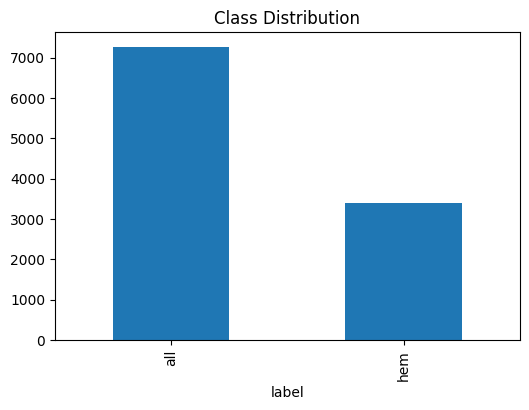

In [64]:
# =============================================================================
# CELL 6 : DATASET STATISTICS
# =============================================================================

print("="*80)

print("DATASET STATISTICS")

print("="*80)

print(

    df["label"]

    .value_counts()

)

print()

print(

    df["fold"]

    .value_counts()

)

plt.figure(

    figsize=(6,4)

)

df["label"].value_counts().plot(

    kind="bar"

)

plt.title(

    "Class Distribution"

)

plt.show()

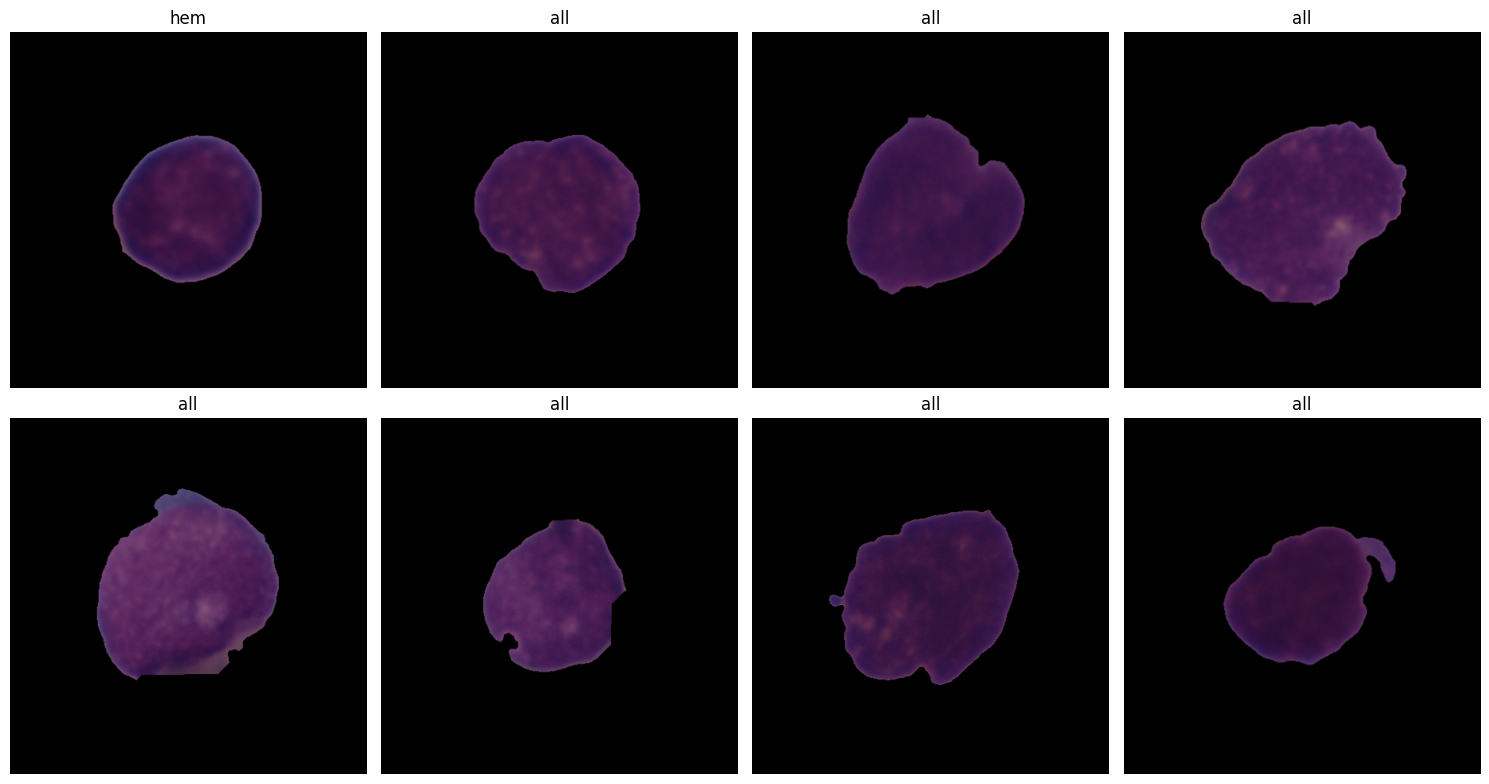

In [65]:
# =============================================================================
# CELL 7 : VISUALIZE SAMPLE IMAGES
# =============================================================================

import matplotlib.pyplot as plt
import random
import cv2

plt.figure(figsize=(15,8))

sample_index = random.sample(range(len(df)), 8)

for i, idx in enumerate(sample_index):

    image = cv2.imread(df.iloc[idx]["image_path"])
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.subplot(2,4,i+1)

    plt.imshow(image)

    plt.title(df.iloc[idx]["label"])

    plt.axis("off")

plt.tight_layout()

plt.show()

In [66]:
# =============================================================================
# CELL 8 : IMAGE PREPROCESSING
# =============================================================================

IMAGE_SIZE = 224

train_transform = A.Compose([

    A.Resize(IMAGE_SIZE, IMAGE_SIZE),

    A.HorizontalFlip(p=0.5),

    A.VerticalFlip(p=0.5),

    A.Rotate(
        limit=20,
        border_mode=cv2.BORDER_REFLECT,
        p=0.5
    ),

    A.RandomBrightnessContrast(
        brightness_limit=0.20,
        contrast_limit=0.20,
        p=0.5
    ),

    A.ShiftScaleRotate(

        shift_limit=0.08,

        scale_limit=0.10,

        rotate_limit=20,

        border_mode=cv2.BORDER_REFLECT,

        p=0.5

    ),

    A.GaussNoise(

        std_range=(0.02,0.08),

        p=0.30

    ),

    A.CoarseDropout(

        num_holes_range=(2,6),

        hole_height_range=(8,20),

        hole_width_range=(8,20),

        fill=0,

        p=0.30

    ),

    A.Normalize(

        mean=(0.485,0.456,0.406),

        std=(0.229,0.224,0.225)

    ),

    ToTensorV2()

])

valid_transform = A.Compose([

    A.Resize(IMAGE_SIZE, IMAGE_SIZE),

    A.Normalize(

        mean=(0.485,0.456,0.406),

        std=(0.229,0.224,0.225)

    ),

    ToTensorV2()

])

print("Transforms Created Successfully")

Transforms Created Successfully


In [77]:
# =============================================================================
# CELL 9 : STRATIFIED TRAIN / VALIDATION SPLIT
# =============================================================================

train_df, valid_df = train_test_split(

    df,

    test_size=0.10,

    random_state=SEED,

    stratify=df["target"],

    shuffle=True

)

train_df = train_df.reset_index(drop=True)

valid_df = valid_df.reset_index(drop=True)

print("="*80)
print("TRAIN / VALIDATION SPLIT")
print("="*80)

print(f"Training Images   : {len(train_df)}")
print(f"Validation Images : {len(valid_df)}")

print("\nTraining Class Distribution")
print(train_df["label"].value_counts())

print("\nValidation Class Distribution")
print(valid_df["label"].value_counts())

print("="*80)

TRAIN / VALIDATION SPLIT
Training Images   : 9594
Validation Images : 1067

Training Class Distribution
label
all    6544
hem    3050
Name: count, dtype: int64

Validation Class Distribution
label
all    728
hem    339
Name: count, dtype: int64


In [86]:
# =============================================================================
# CELL 11 : CUSTOM DATASET CLASS
# =============================================================================

class LeukemiaDataset(Dataset):

    def __init__(self, dataframe, transform=None):

        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):

        return len(self.dataframe)

    def __getitem__(self, index):

        image_path = self.dataframe.loc[index, "image_path"]

        image = cv2.imread(image_path)

        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

        label = int(self.dataframe.loc[index, "target"])

        if self.transform:

            image = self.transform(image=image)["image"]

        return image, label


print("="*80)
print("Custom Dataset Class Created Successfully")
print("="*80)

Custom Dataset Class Created Successfully


In [87]:
# =============================================================================
# CELL 12 : CREATE DATASET OBJECTS
# =============================================================================

train_dataset = LeukemiaDataset(

    dataframe=train_df,

    transform=train_transform

)

valid_dataset = LeukemiaDataset(

    dataframe=valid_df,

    transform=valid_transform

)

print("="*80)
print("DATASET INFORMATION")
print("="*80)

print("Train Dataset      :", len(train_dataset))
print("Validation Dataset :", len(valid_dataset))

print("="*80)

DATASET INFORMATION
Train Dataset      : 9594
Validation Dataset : 1067


In [88]:
# =============================================================================
# CELL 13 : CREATE DATALOADERS
# =============================================================================

BATCH_SIZE = 32

NUM_WORKERS = 2

train_loader = DataLoader(

    train_dataset,

    batch_size=BATCH_SIZE,

    shuffle=True,

    num_workers=NUM_WORKERS,

    pin_memory=True,

    drop_last=False

)

valid_loader = DataLoader(

    valid_dataset,

    batch_size=BATCH_SIZE,

    shuffle=False,

    num_workers=NUM_WORKERS,

    pin_memory=True,

    drop_last=False

)



print("="*80)

print("Train Batches      :", len(train_loader))

print("Validation Batches :", len(valid_loader))



print("="*80)

Train Batches      : 300
Validation Batches : 34


Batch Shape
Images : torch.Size([32, 3, 224, 224])
Labels : torch.Size([32])

Unique Labels : tensor([0, 1])


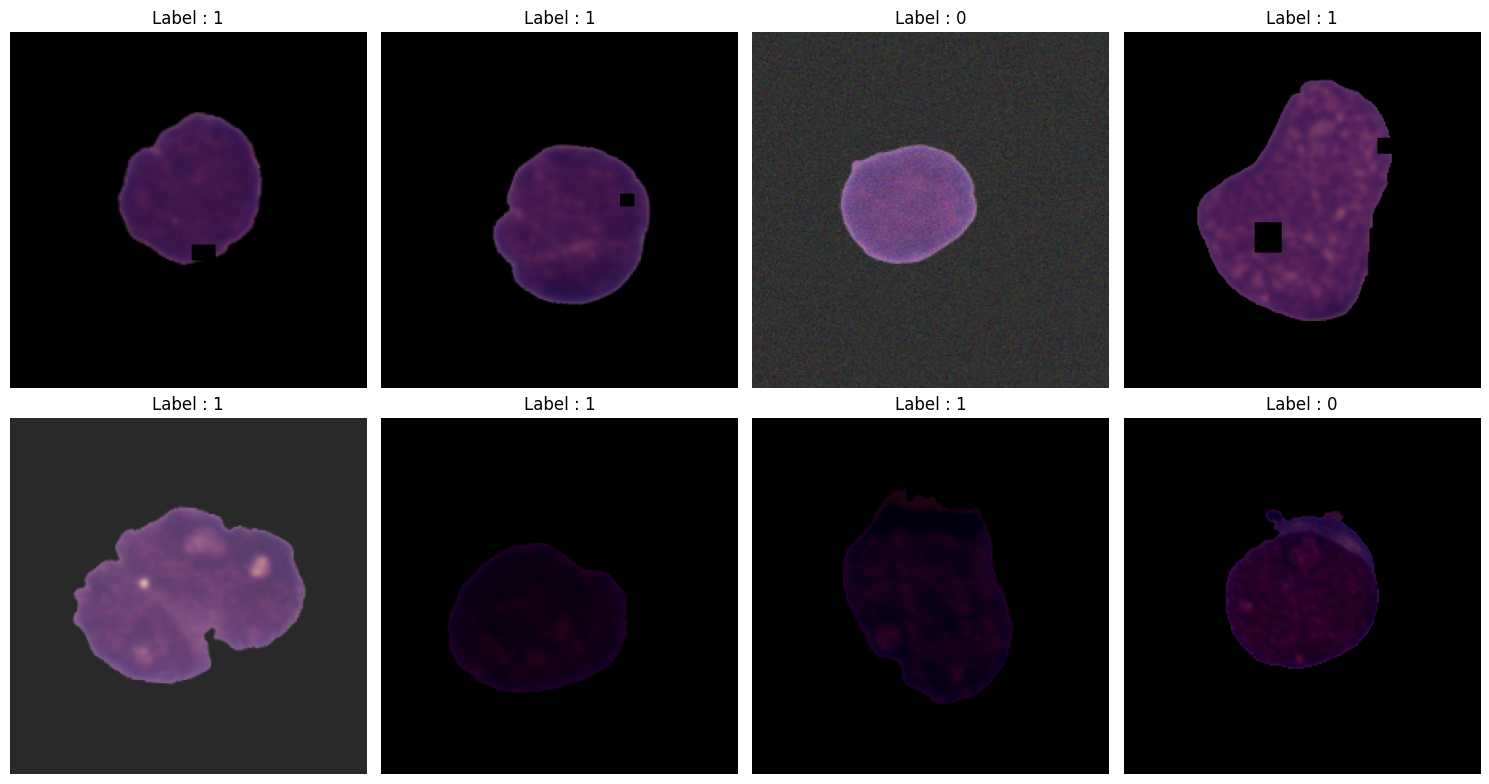

Notebook 1 Completed Successfully


In [89]:
# =============================================================================
# CELL 14 : VERIFY DATALOADER
# =============================================================================

images, labels = next(iter(train_loader))

print("="*80)

print("Batch Shape")

print("="*80)

print("Images :", images.shape)

print("Labels :", labels.shape)

print()

print("Unique Labels :", torch.unique(labels))

plt.figure(figsize=(15,8))

for i in range(8):

    img = images[i].permute(1,2,0).numpy()

    mean = np.array([0.485,0.456,0.406])

    std = np.array([0.229,0.224,0.225])

    img = std * img + mean

    img = np.clip(img,0,1)

    plt.subplot(2,4,i+1)

    plt.imshow(img)

    plt.title(f"Label : {labels[i].item()}")

    plt.axis("off")

plt.tight_layout()

plt.show()

print("="*80)
print("Notebook 1 Completed Successfully")
print("="*80)

In [74]:
import os

test_root = "/kaggle/input/datasets/kaviyam23adr085/lekumiaaa/C-NMC_Leukemia/testing_data"

for root, dirs, files in os.walk(test_root):

    print(root)

    print("Folders :", dirs[:10])

    print("Files :", len(files))

    print("-"*60)

/kaggle/input/datasets/kaviyam23adr085/lekumiaaa/C-NMC_Leukemia/testing_data
Folders : ['C-NMC_test_final_phase_data']
Files : 0
------------------------------------------------------------
/kaggle/input/datasets/kaviyam23adr085/lekumiaaa/C-NMC_Leukemia/testing_data/C-NMC_test_final_phase_data
Folders : []
Files : 2586
------------------------------------------------------------


In [90]:
print(df.head())

print(df.shape)

print(df["label"].value_counts())

print(df["target"].value_counts())

                                          image_path label    fold  target
0  /kaggle/input/datasets/kaviyam23adr085/lekumia...   all  fold_0       1
1  /kaggle/input/datasets/kaviyam23adr085/lekumia...   all  fold_0       1
2  /kaggle/input/datasets/kaviyam23adr085/lekumia...   all  fold_0       1
3  /kaggle/input/datasets/kaviyam23adr085/lekumia...   all  fold_0       1
4  /kaggle/input/datasets/kaviyam23adr085/lekumia...   all  fold_0       1
(10661, 4)
label
all    7272
hem    3389
Name: count, dtype: int64
target
1    7272
0    3389
Name: count, dtype: int64


In [91]:
print(len(train_df))
print(len(valid_df))

print(train_df["label"].value_counts())
print(valid_df["label"].value_counts())

9594
1067
label
all    6544
hem    3050
Name: count, dtype: int64
label
all    728
hem    339
Name: count, dtype: int64


In [92]:
print(len(train_dataset))
print(len(valid_dataset))

9594
1067


In [93]:
print(len(train_loader))
print(len(valid_loader))

300
34


In [94]:
# =============================================================================
# NOTEBOOK 2A
# CELL 1 : IMPORT LIBRARIES
# =============================================================================

import copy
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.auto import tqdm

from sklearn.metrics import (

    accuracy_score,

    precision_score,

    recall_score,

    f1_score,

    roc_auc_score,

    confusion_matrix,

    classification_report,

    roc_curve

)

import torch
import torch.nn as nn
import torch.optim as optim

from transformers import ViTModel

warnings.filterwarnings("ignore")

print("="*80)
print("NOTEBOOK 2A : VISION TRANSFORMER")
print("="*80)

NOTEBOOK 2A : VISION TRANSFORMER


In [97]:
# =============================================================================
# CELL 2 : LOAD VISION TRANSFORMER
# =============================================================================

NUM_CLASSES = 2

model = ViTModel.from_pretrained(

    "google/vit-base-patch16-224-in21k"

)

for param in model.parameters():

    param.requires_grad = True

classifier = nn.Sequential(

    nn.Linear(model.config.hidden_size,512),

    nn.BatchNorm1d(512),

    nn.ReLU(inplace=True),

    nn.Dropout(0.50),

    nn.Linear(512,256),

    nn.BatchNorm1d(256),

    nn.ReLU(inplace=True),

    nn.Dropout(0.40),

    nn.Linear(256,NUM_CLASSES)

)

class ViTClassifier(nn.Module):

    def __init__(self, backbone, classifier):

        super().__init__()

        self.backbone = backbone

        self.classifier = classifier

    def forward(self,x):

        outputs = self.backbone(pixel_values=x)

        features = outputs.last_hidden_state[:,0]

        logits = self.classifier(features)

        return logits

model = ViTClassifier(

    model,

    classifier

)

model = model.to(device)

print(model)

print("="*80)
print("Vision Transformer Loaded Successfully")
print("="*80)

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

ViTClassifier(
  (backbone): ViTModel(
    (embeddings): ViTEmbeddings(
      (patch_embeddings): ViTPatchEmbeddings(
        (projection): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
      )
      (dropout): Dropout(p=0.0, inplace=False)
    )
    (encoder): ViTEncoder(
      (layer): ModuleList(
        (0-11): 12 x ViTLayer(
          (attention): ViTAttention(
            (attention): ViTSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
            )
            (output): ViTSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.0, inplace=False)
            )
          )
          (intermediate): ViTIntermediate(
            (dense): Linear(in_features=768, out_features=3072, bias=True)
            (intermediate_ac

In [105]:
# =============================================================================
# CELL 3 : TRAINING CONFIGURATION
# =============================================================================

EPOCHS = 10

LEARNING_RATE = 5e-5

WEIGHT_DECAY = 1e-4

PATIENCE = 3

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(

    model.parameters(),

    lr=LEARNING_RATE,

    weight_decay=WEIGHT_DECAY

)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(

    optimizer,

    T_max=EPOCHS,

    eta_min=1e-6

)

print("="*80)
print("TRAINING CONFIGURATION")
print("="*80)

print("Epochs        :", EPOCHS)
print("Learning Rate :", LEARNING_RATE)
print("Weight Decay  :", WEIGHT_DECAY)
print("Patience      :", PATIENCE)

print("="*80)

TRAINING CONFIGURATION
Epochs        : 10
Learning Rate : 5e-05
Weight Decay  : 0.0001
Patience      : 3


In [106]:
# =============================================================================
# CELL 4 : TRAINING & VALIDATION FUNCTIONS
# =============================================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# =============================================================================
# TRAINING FUNCTION
# =============================================================================

def train_one_epoch(model, loader, criterion, optimizer):

    model.train()

    running_loss = 0.0

    all_labels = []
    all_preds = []

    for images, labels in tqdm(loader, leave=False):

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        preds = torch.argmax(outputs, dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())

    epoch_loss = running_loss / len(loader)

    epoch_acc = accuracy_score(all_labels, all_preds)

    return epoch_loss, epoch_acc


# =============================================================================
# VALIDATION FUNCTION
# =============================================================================

def validate_one_epoch(model, loader, criterion):

    model.eval()

    running_loss = 0.0

    all_labels = []
    all_preds = []
    all_probs = []

    with torch.no_grad():

        for images, labels in tqdm(loader, leave=False):

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item()

            probs = torch.softmax(outputs, dim=1)

            preds = torch.argmax(probs, dim=1)

            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_probs.extend(probs[:,1].cpu().numpy())

    epoch_loss = running_loss / len(loader)

    accuracy = accuracy_score(all_labels, all_preds)

    precision = precision_score(
        all_labels,
        all_preds,
        zero_division=0
    )

    recall = recall_score(
        all_labels,
        all_preds,
        zero_division=0
    )

    f1 = f1_score(
        all_labels,
        all_preds,
        zero_division=0
    )

    auc = roc_auc_score(
        all_labels,
        all_probs
    )

    return (

        epoch_loss,

        accuracy,

        precision,

        recall,

        f1,

        auc

    )


print("="*80)
print("Training & Validation Functions Created Successfully")
print("="*80)

Training & Validation Functions Created Successfully


In [107]:
# =============================================================================
# CELL 5A (PART 1) : INITIALIZE TRAINING
# =============================================================================

best_accuracy = 0.0
best_epoch = 0
early_stop_counter = 0

train_loss_history = []
valid_loss_history = []

train_acc_history = []
valid_acc_history = []

precision_history = []
recall_history = []
f1_history = []
auc_history = []

print("="*80)
print("TRAINING STARTED")
print("="*80)

TRAINING STARTED


In [108]:
# =============================================================================
# CELL 5 : TRAINING LOOP
# =============================================================================

best_accuracy = 0.0
best_epoch = 0
early_stop_counter = 0

train_loss_history = []
valid_loss_history = []

train_acc_history = []
valid_acc_history = []

precision_history = []
recall_history = []
f1_history = []
auc_history = []

print("="*80)
print("TRAINING STARTED")
print("="*80)

for epoch in range(EPOCHS):

    print(f"\n{'='*80}")
    print(f"Epoch [{epoch+1}/{EPOCHS}]")
    print(f"{'='*80}")

    # -------------------- TRAIN --------------------
    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer
    )

    # ------------------ VALIDATION -----------------
    valid_loss, valid_acc, precision, recall, f1, auc = validate_one_epoch(
        model,
        valid_loader,
        criterion
    )

    scheduler.step()

    train_loss_history.append(train_loss)
    valid_loss_history.append(valid_loss)

    train_acc_history.append(train_acc)
    valid_acc_history.append(valid_acc)

    precision_history.append(precision)
    recall_history.append(recall)
    f1_history.append(f1)
    auc_history.append(auc)

    # ================= PRINT METRICS =================

    print(f"Train Loss     : {train_loss:.4f}")
    print(f"Train Accuracy : {train_acc:.4f}")

    print(f"Valid Loss     : {valid_loss:.4f}")
    print(f"Valid Accuracy : {valid_acc:.4f}")

    print(f"Precision      : {precision:.4f}")
    print(f"Recall         : {recall:.4f}")
    print(f"F1 Score       : {f1:.4f}")
    print(f"AUC Score      : {auc:.4f}")

    print(f"Learning Rate  : {optimizer.param_groups[0]['lr']:.8f}")

    # ================= SAVE BEST MODEL =================

    if valid_acc > best_accuracy:

        best_accuracy = valid_acc
        best_epoch = epoch + 1

        torch.save(
            model.state_dict(),
            "best_vit_model.pth"
        )

        early_stop_counter = 0

        print("✅ Best Model Saved")

    else:

        early_stop_counter += 1

        print(f"No Improvement ({early_stop_counter}/{PATIENCE})")

    # ================= EARLY STOPPING =================

    if early_stop_counter >= PATIENCE:

        print("\n🛑 Early Stopping Triggered")

        break

print("\n" + "="*80)
print("TRAINING COMPLETED")
print("="*80)

print(f"Best Validation Accuracy : {best_accuracy:.4f}")
print(f"Best Epoch               : {best_epoch}")

TRAINING STARTED

Epoch [1/10]


  0%|          | 0/300 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7bd4a7f66ca0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7bd4a7f66ca0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 16

  0%|          | 0/34 [00:00<?, ?it/s]

Train Loss     : 0.2821
Train Accuracy : 0.8862
Valid Loss     : 0.2214
Valid Accuracy : 0.9185
Precision      : 0.9508
Recall         : 0.9286
F1 Score       : 0.9395
AUC Score      : 0.9705
Learning Rate  : 0.00004880
✅ Best Model Saved

Epoch [2/10]


...

Train Loss     : 0.1356
Train Accuracy : 0.9511
Valid Loss     : 0.1068
Valid Accuracy : 0.9616
Precision      : 0.9699
Recall         : 0.9739
F1 Score       : 0.9719
AUC Score      : 0.9918
Learning Rate  : 0.00000220
✅ Best Model Saved

Epoch [10/10]


  0%|          | 0/300 [00:00<?, ?it/s]

  0%|          | 0/34 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7bd4a7f66ca0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7bd4a7f66ca0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 16

Train Loss     : 0.1302
Train Accuracy : 0.9508
Valid Loss     : 0.0993
Valid Accuracy : 0.9597
Precision      : 0.9635
Recall         : 0.9780
F1 Score       : 0.9707
AUC Score      : 0.9924
Learning Rate  : 0.00000100
No Improvement (1/3)

TRAINING COMPLETED
Best Validation Accuracy : 0.9616
Best Epoch               : 9


In [109]:
# =============================================================================
# CELL 6 : LOAD BEST MODEL & FINAL EVALUATION
# =============================================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# ---------------- LOAD BEST MODEL ----------------

model.load_state_dict(torch.load("best_vit_model.pth"))

model.eval()

print("="*80)
print("✅ Best model loaded successfully.")
print("="*80)

all_labels = []
all_preds = []
all_probs = []

with torch.no_grad():

    for images, labels in valid_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        probs = torch.softmax(outputs, dim=1)

        preds = torch.argmax(probs, dim=1)

        all_labels.extend(labels.cpu().numpy())

        all_preds.extend(preds.cpu().numpy())

        all_probs.extend(probs[:,1].cpu().numpy())

# ---------------- FINAL METRICS ----------------

accuracy = accuracy_score(all_labels, all_preds)

precision = precision_score(
    all_labels,
    all_preds,
    zero_division=0
)

recall = recall_score(
    all_labels,
    all_preds,
    zero_division=0
)

f1 = f1_score(
    all_labels,
    all_preds,
    zero_division=0
)

auc = roc_auc_score(
    all_labels,
    all_probs
)

print("\n" + "="*80)
print("FINAL PERFORMANCE")
print("="*80)

print("Model          : Vision Transformer")
print(f"Accuracy       : {accuracy:.4f}")
print(f"Precision      : {precision:.4f}")
print(f"Recall         : {recall:.4f}")
print(f"F1 Score       : {f1:.4f}")
print(f"AUC Score      : {auc:.4f}")
print(f"Best Epoch     : {best_epoch}")

print("="*80)

✅ Best model loaded successfully.

FINAL PERFORMANCE
Model          : Vision Transformer
Accuracy       : 0.9616
Precision      : 0.9699
Recall         : 0.9739
F1 Score       : 0.9719
AUC Score      : 0.9918
Best Epoch     : 9


CONFUSION MATRIX
[[317  22]
 [ 19 709]]


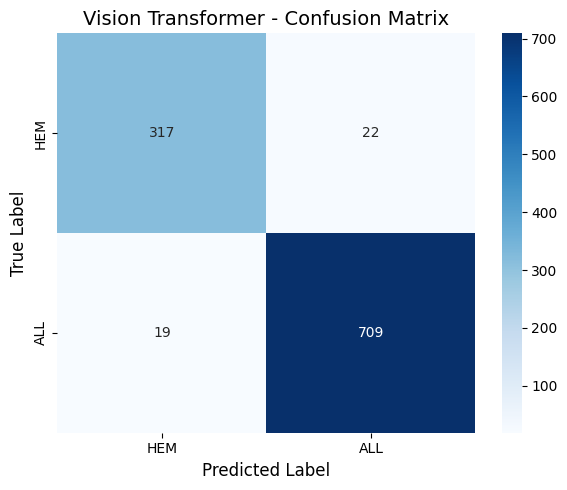


CLASSIFICATION REPORT
              precision    recall  f1-score   support

         HEM     0.9435    0.9351    0.9393       339
         ALL     0.9699    0.9739    0.9719       728

    accuracy                         0.9616      1067
   macro avg     0.9567    0.9545    0.9556      1067
weighted avg     0.9615    0.9616    0.9615      1067

✅ Classification report saved as 'vit_classification_report.txt'


In [110]:
# =============================================================================
# CELL 7 : CONFUSION MATRIX & CLASSIFICATION REPORT
# =============================================================================

from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------------
# CONFUSION MATRIX
# ------------------------------------------------------------------

cm = confusion_matrix(all_labels, all_preds)

print("="*80)
print("CONFUSION MATRIX")
print("="*80)
print(cm)

# ------------------------------------------------------------------
# PLOT CONFUSION MATRIX
# ------------------------------------------------------------------

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["HEM","ALL"],
    yticklabels=["HEM","ALL"]
)

plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("True Label", fontsize=12)
plt.title("Vision Transformer - Confusion Matrix", fontsize=14)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------------
# CLASSIFICATION REPORT
# ------------------------------------------------------------------

print("\n" + "="*80)
print("CLASSIFICATION REPORT")
print("="*80)

report = classification_report(
    all_labels,
    all_preds,
    target_names=["HEM","ALL"],
    digits=4
)

print(report)

# ------------------------------------------------------------------
# SAVE CLASSIFICATION REPORT
# ------------------------------------------------------------------

with open("vit_classification_report.txt", "w") as f:
    f.write(report)

print("✅ Classification report saved as 'vit_classification_report.txt'")

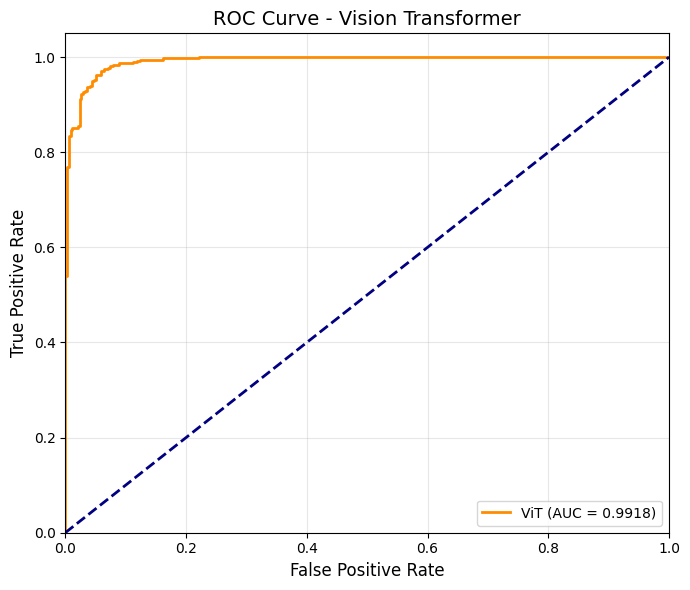

AUC Score : 0.9918


In [111]:
# =============================================================================
# CELL 8 : ROC CURVE
# =============================================================================

from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# ------------------------------------------------------------------
# ROC CURVE
# ------------------------------------------------------------------

fpr, tpr, thresholds = roc_curve(all_labels, all_probs)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7,6))

plt.plot(
    fpr,
    tpr,
    color="darkorange",
    linewidth=2,
    label=f"ViT (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0,1],
    [0,1],
    linestyle="--",
    color="navy",
    linewidth=2
)

plt.xlim([0.0,1.0])
plt.ylim([0.0,1.05])

plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)

plt.title("ROC Curve - Vision Transformer", fontsize=14)

plt.legend(loc="lower right")

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

print("="*80)
print(f"AUC Score : {roc_auc:.4f}")
print("="*80)

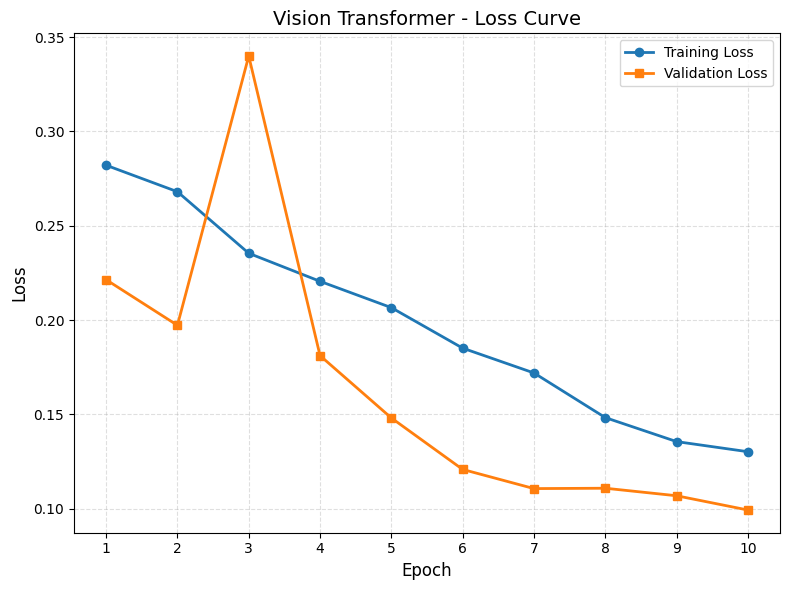

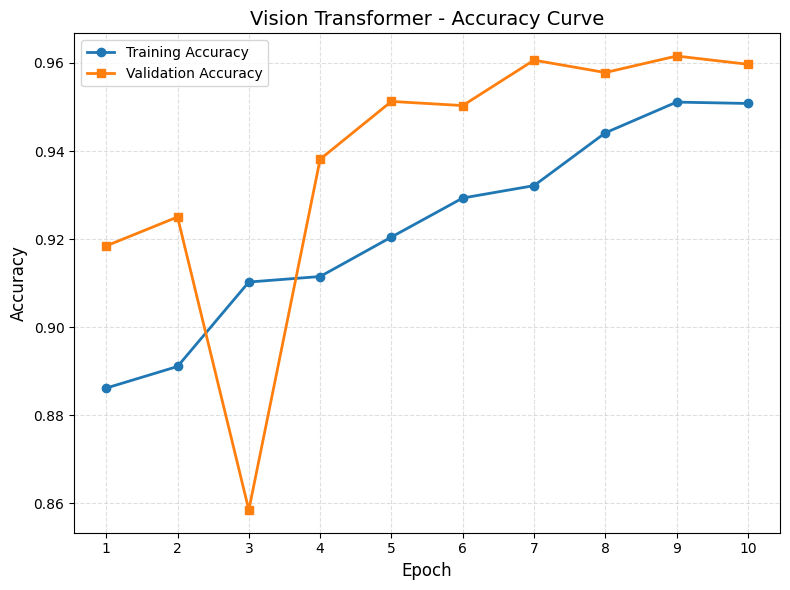

✅ Loss Curve Generated
✅ Accuracy Curve Generated


In [112]:
# =============================================================================
# CELL 9 : TRAINING CURVES
# =============================================================================

import matplotlib.pyplot as plt

epochs = range(1, len(train_loss_history) + 1)

# -----------------------------------------------------------------------------
# LOSS CURVE
# -----------------------------------------------------------------------------

plt.figure(figsize=(8,6))

plt.plot(
    epochs,
    train_loss_history,
    marker='o',
    linewidth=2,
    label="Training Loss"
)

plt.plot(
    epochs,
    valid_loss_history,
    marker='s',
    linewidth=2,
    label="Validation Loss"
)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss", fontsize=12)
plt.title("Vision Transformer - Loss Curve", fontsize=14)

plt.xticks(epochs)
plt.grid(True, linestyle="--", alpha=0.4)

plt.legend()

plt.tight_layout()
plt.show()


# -----------------------------------------------------------------------------
# ACCURACY CURVE
# -----------------------------------------------------------------------------

plt.figure(figsize=(8,6))

plt.plot(
    epochs,
    train_acc_history,
    marker='o',
    linewidth=2,
    label="Training Accuracy"
)

plt.plot(
    epochs,
    valid_acc_history,
    marker='s',
    linewidth=2,
    label="Validation Accuracy"
)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Accuracy", fontsize=12)
plt.title("Vision Transformer - Accuracy Curve", fontsize=14)

plt.xticks(epochs)
plt.grid(True, linestyle="--", alpha=0.4)

plt.legend()

plt.tight_layout()
plt.show()


print("="*80)
print("✅ Loss Curve Generated")
print("✅ Accuracy Curve Generated")
print("="*80)

In [113]:
# =============================================================================
# CELL 10 : SAVE FINAL RESULTS
# =============================================================================

import pandas as pd

results = pd.DataFrame({

    "Model": ["Vision Transformer"],

    "Accuracy": [accuracy],

    "Precision": [precision],

    "Recall": [recall],

    "F1 Score": [f1],

    "AUC Score": [auc],

    "Best Validation Accuracy": [best_accuracy],

    "Best Epoch": [best_epoch]

})

results.to_csv("vit_results.csv", index=False)

print("="*80)
print("FINAL RESULTS")
print("="*80)

print(results)

print("\n✅ Results saved as 'vit_results.csv'")

print("="*80)

FINAL RESULTS
                Model  Accuracy  Precision    Recall  F1 Score  \
0  Vision Transformer  0.961575   0.969904  0.973901  0.971899   

                          AUC Score  Best Validation Accuracy  Best Epoch  
0  <function auc at 0x7bd4464959e0>                  0.961575           9  

✅ Results saved as 'vit_results.csv'


In [114]:
# =============================================================================
# NOTEBOOK 2B
# CELL 1 : IMPORT LIBRARIES
# =============================================================================

import copy
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.auto import tqdm

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import models

warnings.filterwarnings("ignore")

print("="*80)
print("NOTEBOOK 2B : EFFICIENTNET-B3")
print("="*80)

NOTEBOOK 2B : EFFICIENTNET-B3


In [115]:
# =============================================================================
# CELL 2 : LOAD EFFICIENTNET-B3
# =============================================================================

NUM_CLASSES = 2

# Load pretrained EfficientNet-B3
model = models.efficientnet_b3(
    weights=models.EfficientNet_B3_Weights.DEFAULT
)

# Fine-tune entire network
for param in model.parameters():
    param.requires_grad = True

# Replace classifier
in_features = model.classifier[1].in_features

model.classifier = nn.Sequential(

    nn.Dropout(0.4),

    nn.Linear(in_features, 512),

    nn.BatchNorm1d(512),

    nn.ReLU(inplace=True),

    nn.Dropout(0.3),

    nn.Linear(512, 256),

    nn.BatchNorm1d(256),

    nn.ReLU(inplace=True),

    nn.Dropout(0.2),

    nn.Linear(256, NUM_CLASSES)

)

model = model.to(device)

print(model)

print("="*80)
print("EfficientNet-B3 Loaded Successfully")
print("="*80)

Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth


100%|██████████| 47.2M/47.2M [00:00<00:00, 190MB/s]


EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 40, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(40, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(40, 40, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=40, bias=False)
            (1): BatchNorm2d(40, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(40, 10, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(10, 40, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          (2): Conv2dNormActiv

In [116]:
# =============================================================================
# CELL 3 : TRAINING CONFIGURATION
# =============================================================================

EPOCHS = 10

LEARNING_RATE = 3e-4

WEIGHT_DECAY = 1e-4

PATIENCE = 3

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(

    model.parameters(),

    lr=LEARNING_RATE,

    weight_decay=WEIGHT_DECAY

)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(

    optimizer,

    T_max=EPOCHS,

    eta_min=1e-6

)

print("="*80)

print("Epochs        :", EPOCHS)
print("Learning Rate :", LEARNING_RATE)
print("Weight Decay  :", WEIGHT_DECAY)
print("Patience      :", PATIENCE)

print("="*80)

Epochs        : 10
Learning Rate : 0.0003
Weight Decay  : 0.0001
Patience      : 3


In [117]:
# =============================================================================
# CELL 4 : TRAINING & VALIDATION FUNCTIONS
# =============================================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# =============================================================================
# TRAINING FUNCTION
# =============================================================================

def train_one_epoch(model, loader, criterion, optimizer):

    model.train()

    running_loss = 0.0

    all_labels = []
    all_preds = []

    for images, labels in tqdm(loader, leave=False):

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        preds = torch.argmax(outputs, dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())

    epoch_loss = running_loss / len(loader)

    epoch_acc = accuracy_score(all_labels, all_preds)

    return epoch_loss, epoch_acc


# =============================================================================
# VALIDATION FUNCTION
# =============================================================================

def validate_one_epoch(model, loader, criterion):

    model.eval()

    running_loss = 0.0

    all_labels = []
    all_preds = []
    all_probs = []

    with torch.no_grad():

        for images, labels in tqdm(loader, leave=False):

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item()

            probs = torch.softmax(outputs, dim=1)

            preds = torch.argmax(probs, dim=1)

            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_probs.extend(probs[:,1].cpu().numpy())

    epoch_loss = running_loss / len(loader)

    accuracy = accuracy_score(all_labels, all_preds)

    precision = precision_score(
        all_labels,
        all_preds,
        zero_division=0
    )

    recall = recall_score(
        all_labels,
        all_preds,
        zero_division=0
    )

    f1 = f1_score(
        all_labels,
        all_preds,
        zero_division=0
    )

    auc = roc_auc_score(
        all_labels,
        all_probs
    )

    return (
        epoch_loss,
        accuracy,
        precision,
        recall,
        f1,
        auc
    )

print("="*80)
print("Training & Validation Functions Created Successfully")
print("="*80)

Training & Validation Functions Created Successfully


In [118]:
# =============================================================================
# CELL 5 : TRAINING LOOP
# =============================================================================

best_accuracy = 0.0
best_epoch = 0
early_stop_counter = 0

train_loss_history = []
valid_loss_history = []

train_acc_history = []
valid_acc_history = []

precision_history = []
recall_history = []
f1_history = []
auc_history = []

print("="*80)
print("TRAINING STARTED")
print("="*80)

for epoch in range(EPOCHS):

    print(f"\n{'='*80}")
    print(f"Epoch [{epoch+1}/{EPOCHS}]")
    print("="*80)

    # ================= TRAIN =================

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer
    )

    # ================ VALIDATION ================

    valid_loss, valid_acc, precision, recall, f1, auc = validate_one_epoch(
        model,
        valid_loader,
        criterion
    )

    scheduler.step()

    train_loss_history.append(train_loss)
    valid_loss_history.append(valid_loss)

    train_acc_history.append(train_acc)
    valid_acc_history.append(valid_acc)

    precision_history.append(precision)
    recall_history.append(recall)
    f1_history.append(f1)
    auc_history.append(auc)

    # ================= PRINT =================

    print(f"Train Loss     : {train_loss:.4f}")
    print(f"Train Accuracy : {train_acc:.4f}")

    print(f"Valid Loss     : {valid_loss:.4f}")
    print(f"Valid Accuracy : {valid_acc:.4f}")

    print(f"Precision      : {precision:.4f}")
    print(f"Recall         : {recall:.4f}")
    print(f"F1 Score       : {f1:.4f}")
    print(f"AUC Score      : {auc:.4f}")

    print(f"Learning Rate  : {optimizer.param_groups[0]['lr']:.8f}")

    # ================= SAVE BEST MODEL =================

    if valid_acc > best_accuracy:

        best_accuracy = valid_acc
        best_epoch = epoch + 1

        torch.save(
            model.state_dict(),
            "best_efficientnetb3_model.pth"
        )

        early_stop_counter = 0

        print("✅ Best Model Saved")

    else:

        early_stop_counter += 1

        print(f"No Improvement ({early_stop_counter}/{PATIENCE})")

    # ================= EARLY STOPPING =================

    if early_stop_counter >= PATIENCE:

        print("\n🛑 Early Stopping Triggered")

        break

print("\n" + "="*80)
print("TRAINING COMPLETED")
print("="*80)

print(f"Best Validation Accuracy : {best_accuracy:.4f}")
print(f"Best Epoch               : {best_epoch}")

TRAINING STARTED

Epoch [1/10]


  0%|          | 0/300 [00:00<?, ?it/s]

  0%|          | 0/34 [00:00<?, ?it/s]

Train Loss     : 0.4327
Train Accuracy : 0.8155
Valid Loss     : 0.3261
Valid Accuracy : 0.8679
Precision      : 0.9105
Recall         : 0.8942
F1 Score       : 0.9023
AUC Score      : 0.9239
Learning Rate  : 0.00029268
✅ Best Model Saved

Epoch [2/10]


  0%|          | 0/300 [00:00<?, ?it/s]

...

  0%|          | 0/34 [00:00<?, ?it/s]

Train Loss     : 0.1718
Train Accuracy : 0.9329
Valid Loss     : 0.1393
Valid Accuracy : 0.9447
Precision      : 0.9576
Recall         : 0.9615
F1 Score       : 0.9596
AUC Score      : 0.9856
Learning Rate  : 0.00000832
No Improvement (1/3)

Epoch [10/10]


  0%|          | 0/300 [00:00<?, ?it/s]

  0%|          | 0/34 [00:00<?, ?it/s]

Train Loss     : 0.1587
Train Accuracy : 0.9396
Valid Loss     : 0.1299
Valid Accuracy : 0.9466
Precision      : 0.9565
Recall         : 0.9657
F1 Score       : 0.9610
AUC Score      : 0.9862
Learning Rate  : 0.00000100
No Improvement (2/3)

TRAINING COMPLETED
Best Validation Accuracy : 0.9485
Best Epoch               : 8


In [119]:
# =============================================================================
# CELL 6 : LOAD BEST MODEL & FINAL EVALUATION
# =============================================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# ---------------- LOAD BEST MODEL ----------------

model.load_state_dict(torch.load("best_efficientnetb3_model.pth"))

model.eval()

print("="*80)
print("✅ Best EfficientNet-B3 model loaded successfully.")
print("="*80)

all_labels = []
all_preds = []
all_probs = []

with torch.no_grad():

    for images, labels in valid_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        probs = torch.softmax(outputs, dim=1)

        preds = torch.argmax(probs, dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())
        all_probs.extend(probs[:, 1].cpu().numpy())

# ---------------- FINAL METRICS ----------------

accuracy = accuracy_score(all_labels, all_preds)

precision = precision_score(
    all_labels,
    all_preds,
    zero_division=0
)

recall = recall_score(
    all_labels,
    all_preds,
    zero_division=0
)

f1 = f1_score(
    all_labels,
    all_preds,
    zero_division=0
)

auc = roc_auc_score(
    all_labels,
    all_probs
)

print("\n" + "="*80)
print("FINAL PERFORMANCE")
print("="*80)

print("Model          : EfficientNet-B3")
print(f"Accuracy       : {accuracy:.4f}")
print(f"Precision      : {precision:.4f}")
print(f"Recall         : {recall:.4f}")
print(f"F1 Score       : {f1:.4f}")
print(f"AUC Score      : {auc:.4f}")
print(f"Best Epoch     : {best_epoch}")

print("="*80)

✅ Best EfficientNet-B3 model loaded successfully.


Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7bd4a7f66ca0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    if w.is_alive():
       ^^^^^^^^^^^^
  File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
    Exception ignored in:  <function _MultiProcessingDataLoaderIter.__del__ at 0x7bd4a7f66ca0> 
Traceback (most recent call last):
   File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
      self._shutdown_workers() 
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
     ^if w.is_alive():^
^^ ^ ^ ^ ^ ^ ^ ^^^^^^^^^^^^^^^


FINAL PERFORMANCE
Model          : EfficientNet-B3
Accuracy       : 0.9485
Precision      : 0.9529
Recall         : 0.9725
F1 Score       : 0.9626
AUC Score      : 0.9842
Best Epoch     : 8


CONFUSION MATRIX
[[304  35]
 [ 20 708]]


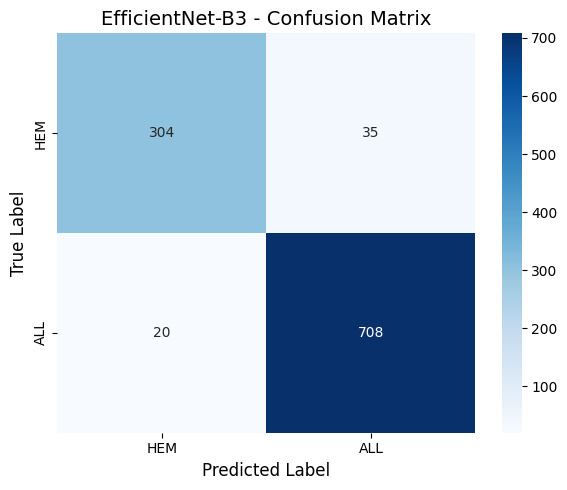


CLASSIFICATION REPORT
              precision    recall  f1-score   support

         HEM     0.9383    0.8968    0.9170       339
         ALL     0.9529    0.9725    0.9626       728

    accuracy                         0.9485      1067
   macro avg     0.9456    0.9346    0.9398      1067
weighted avg     0.9482    0.9485    0.9481      1067


✅ Classification report saved as 'efficientnetb3_classification_report.txt'


In [120]:
# =============================================================================
# CELL 7 : CONFUSION MATRIX & CLASSIFICATION REPORT
# =============================================================================

from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# -----------------------------------------------------------------------------
# CONFUSION MATRIX
# -----------------------------------------------------------------------------

cm = confusion_matrix(all_labels, all_preds)

print("="*80)
print("CONFUSION MATRIX")
print("="*80)
print(cm)

# -----------------------------------------------------------------------------
# PLOT CONFUSION MATRIX
# -----------------------------------------------------------------------------

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["HEM","ALL"],
    yticklabels=["HEM","ALL"]
)

plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("True Label", fontsize=12)
plt.title("EfficientNet-B3 - Confusion Matrix", fontsize=14)

plt.tight_layout()
plt.show()

# -----------------------------------------------------------------------------
# CLASSIFICATION REPORT
# -----------------------------------------------------------------------------

print("\n" + "="*80)
print("CLASSIFICATION REPORT")
print("="*80)

report = classification_report(
    all_labels,
    all_preds,
    target_names=["HEM", "ALL"],
    digits=4
)

print(report)

# -----------------------------------------------------------------------------
# SAVE REPORT
# -----------------------------------------------------------------------------

with open("efficientnetb3_classification_report.txt", "w") as f:
    f.write(report)

print("\n✅ Classification report saved as 'efficientnetb3_classification_report.txt'")

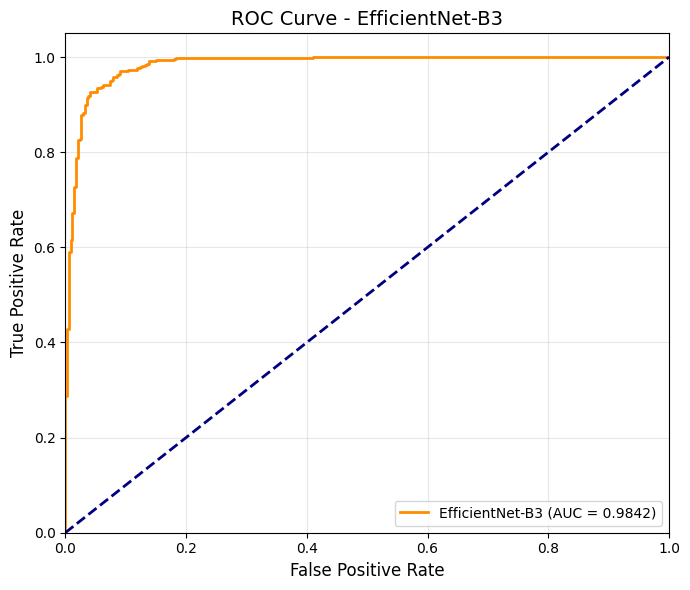

AUC Score : 0.9842


In [121]:
# =============================================================================
# CELL 8 : ROC CURVE
# =============================================================================

from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------------
# ROC CURVE
# -----------------------------------------------------------------------------

fpr, tpr, thresholds = roc_curve(all_labels, all_probs)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7,6))

plt.plot(
    fpr,
    tpr,
    color="darkorange",
    linewidth=2,
    label=f"EfficientNet-B3 (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0,1],
    [0,1],
    linestyle="--",
    color="navy",
    linewidth=2
)

plt.xlim([0.0,1.0])
plt.ylim([0.0,1.05])

plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)

plt.title("ROC Curve - EfficientNet-B3", fontsize=14)

plt.legend(loc="lower right")

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

print("="*80)
print(f"AUC Score : {roc_auc:.4f}")
print("="*80)

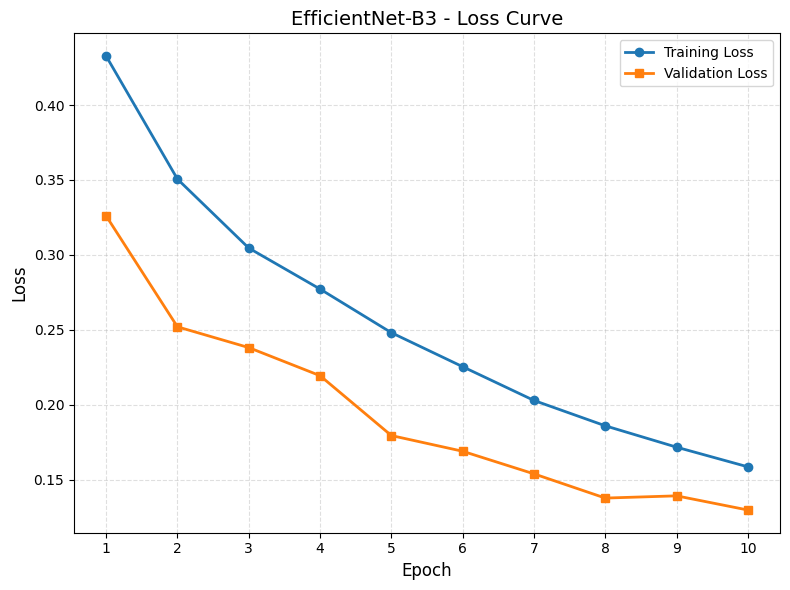

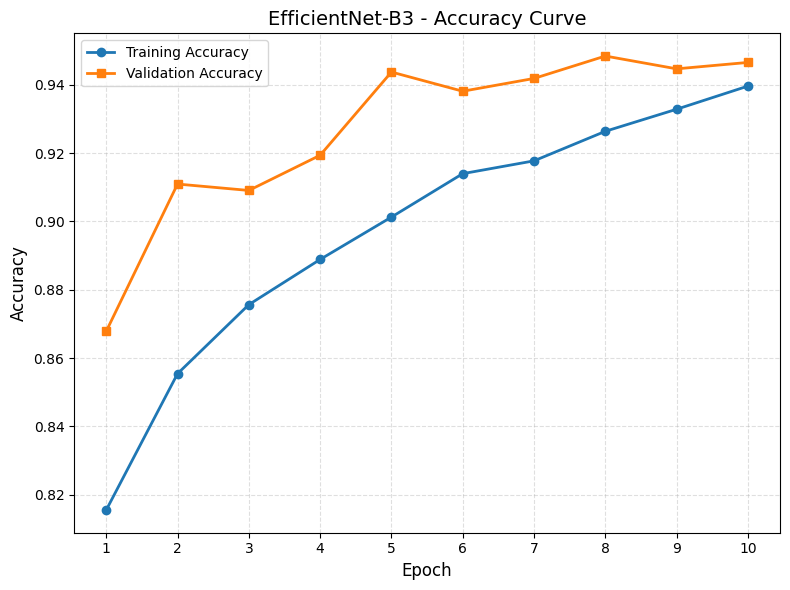

✅ Loss Curve Generated
✅ Accuracy Curve Generated


In [122]:
# =============================================================================
# CELL 9 : TRAINING CURVES
# =============================================================================

import matplotlib.pyplot as plt

epochs = range(1, len(train_loss_history) + 1)

# -----------------------------------------------------------------------------
# LOSS CURVE
# -----------------------------------------------------------------------------

plt.figure(figsize=(8,6))

plt.plot(
    epochs,
    train_loss_history,
    marker='o',
    linewidth=2,
    label="Training Loss"
)

plt.plot(
    epochs,
    valid_loss_history,
    marker='s',
    linewidth=2,
    label="Validation Loss"
)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss", fontsize=12)
plt.title("EfficientNet-B3 - Loss Curve", fontsize=14)

plt.xticks(epochs)
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()

plt.tight_layout()
plt.show()

# -----------------------------------------------------------------------------
# ACCURACY CURVE
# -----------------------------------------------------------------------------

plt.figure(figsize=(8,6))

plt.plot(
    epochs,
    train_acc_history,
    marker='o',
    linewidth=2,
    label="Training Accuracy"
)

plt.plot(
    epochs,
    valid_acc_history,
    marker='s',
    linewidth=2,
    label="Validation Accuracy"
)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Accuracy", fontsize=12)
plt.title("EfficientNet-B3 - Accuracy Curve", fontsize=14)

plt.xticks(epochs)
plt.grid(True, linestyle="--", alpha=0.4)
plt.legend()

plt.tight_layout()
plt.show()

print("="*80)
print("✅ Loss Curve Generated")
print("✅ Accuracy Curve Generated")
print("="*80)

In [123]:
# =============================================================================
# CELL 10 : SAVE FINAL RESULTS
# =============================================================================

import pandas as pd

results = pd.DataFrame({

    "Model": ["EfficientNet-B3"],

    "Accuracy": [accuracy],

    "Precision": [precision],

    "Recall": [recall],

    "F1 Score": [f1],

    "AUC Score": [auc],

    "Best Validation Accuracy": [best_accuracy],

    "Best Epoch": [best_epoch]

})

results.to_csv("efficientnetb3_results.csv", index=False)

print("="*80)
print("FINAL RESULTS")
print("="*80)

print(results)

print("\n✅ Results saved as 'efficientnetb3_results.csv'")

print("="*80)

FINAL RESULTS
             Model  Accuracy  Precision    Recall  F1 Score  \
0  EfficientNet-B3  0.948454   0.952894  0.972527   0.96261   

                          AUC Score  Best Validation Accuracy  Best Epoch  
0  <function auc at 0x7bd4464959e0>                  0.948454           8  

✅ Results saved as 'efficientnetb3_results.csv'


In [124]:
# =============================================================================
# NOTEBOOK 2C
# CELL 1 : IMPORT LIBRARIES
# =============================================================================

import copy
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tqdm.auto import tqdm

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import models

warnings.filterwarnings("ignore")

print("="*80)
print("NOTEBOOK 2C : DENSENET121")
print("="*80)

NOTEBOOK 2C : DENSENET121


In [125]:
# =============================================================================
# CELL 2 : LOAD DENSENET121
# =============================================================================

NUM_CLASSES = 2

# Load pretrained DenseNet121
model = models.densenet121(
    weights=models.DenseNet121_Weights.DEFAULT
)

# Fine-tune entire network
for param in model.parameters():
    param.requires_grad = True

# Replace classifier
in_features = model.classifier.in_features

model.classifier = nn.Sequential(

    nn.Linear(in_features, 512),

    nn.BatchNorm1d(512),

    nn.ReLU(inplace=True),

    nn.Dropout(0.40),

    nn.Linear(512,256),

    nn.BatchNorm1d(256),

    nn.ReLU(inplace=True),

    nn.Dropout(0.30),

    nn.Linear(256,NUM_CLASSES)

)

model = model.to(device)

print(model)

print("="*80)
print("DenseNet121 Loaded Successfully")
print("="*80)

Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 197MB/s]


DenseNet(
  (features): Sequential(
    (conv0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (norm0): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu0): ReLU(inplace=True)
    (pool0): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (denseblock1): _DenseBlock(
      (denselayer1): _DenseLayer(
        (norm1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu1): ReLU(inplace=True)
        (conv1): Conv2d(64, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (norm2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu2): ReLU(inplace=True)
        (conv2): Conv2d(128, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      )
      (denselayer2): _DenseLayer(
        (norm1): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu

In [127]:
# =============================================================================
# CELL 3 : TRAINING CONFIGURATION
# =============================================================================

EPOCHS = 10

LEARNING_RATE = 3e-4

WEIGHT_DECAY = 1e-4

PATIENCE = 3

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(

    model.parameters(),

    lr=LEARNING_RATE,

    weight_decay=WEIGHT_DECAY

)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(

    optimizer,

    T_max=EPOCHS,

    eta_min=1e-6

)

print("="*80)

print("Epochs        :",EPOCHS)
print("Learning Rate :",LEARNING_RATE)
print("Weight Decay  :",WEIGHT_DECAY)
print("Patience      :",PATIENCE)

print("="*80)

Epochs        : 10
Learning Rate : 0.0003
Weight Decay  : 0.0001
Patience      : 3


In [128]:
# =============================================================================
# CELL 4 : TRAINING & VALIDATION FUNCTIONS
# =============================================================================

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# =============================================================================
# TRAINING FUNCTION
# =============================================================================

def train_one_epoch(model, loader, criterion, optimizer):

    model.train()

    running_loss = 0.0

    all_labels = []
    all_preds = []

    for images, labels in tqdm(loader, leave=False):

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        preds = torch.argmax(outputs, dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())

    epoch_loss = running_loss / len(loader)

    epoch_acc = accuracy_score(all_labels, all_preds)

    return epoch_loss, epoch_acc


# =============================================================================
# VALIDATION FUNCTION
# =============================================================================

def validate_one_epoch(model, loader, criterion):

    model.eval()

    running_loss = 0.0

    all_labels = []
    all_preds = []
    all_probs = []

    with torch.no_grad():

        for images, labels in tqdm(loader, leave=False):

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item()

            probs = torch.softmax(outputs, dim=1)

            preds = torch.argmax(probs, dim=1)

            all_labels.extend(labels.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_probs.extend(probs[:,1].cpu().numpy())

    epoch_loss = running_loss / len(loader)

    accuracy = accuracy_score(all_labels, all_preds)

    precision = precision_score(
        all_labels,
        all_preds,
        zero_division=0
    )

    recall = recall_score(
        all_labels,
        all_preds,
        zero_division=0
    )

    f1 = f1_score(
        all_labels,
        all_preds,
        zero_division=0
    )

    auc = roc_auc_score(
        all_labels,
        all_probs
    )

    return (
        epoch_loss,
        accuracy,
        precision,
        recall,
        f1,
        auc
    )


print("="*80)
print("Training & Validation Functions Created Successfully")
print("="*80)

Training & Validation Functions Created Successfully


In [133]:
# =============================================================================
# CELL 5 : TRAINING LOOP
# =============================================================================

best_accuracy = 0.0
best_epoch = 0
early_stop_counter = 0

train_loss_history = []
valid_loss_history = []

train_acc_history = []
valid_acc_history = []

precision_history = []
recall_history = []
f1_history = []
auc_history = []

print("="*80)
print("TRAINING STARTED")
print("="*80)

for epoch in range(EPOCHS):

    print(f"\n{'='*80}")
    print(f"Epoch [{epoch+1}/{EPOCHS}]")
    print("="*80)

    # ================= TRAIN =================

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer
    )

    # ================ VALIDATION ================

    valid_loss, valid_acc, precision, recall, f1, auc = validate_one_epoch(
        model,
        valid_loader,
        criterion
    )

    scheduler.step()

    train_loss_history.append(train_loss)
    valid_loss_history.append(valid_loss)

    train_acc_history.append(train_acc)
    valid_acc_history.append(valid_acc)

    precision_history.append(precision)
    recall_history.append(recall)
    f1_history.append(f1)
    auc_history.append(auc)

    # ================= PRINT =================

    print(f"Train Loss     : {train_loss:.4f}")
    print(f"Train Accuracy : {train_acc:.4f}")

    print(f"Valid Loss     : {valid_loss:.4f}")
    print(f"Valid Accuracy : {valid_acc:.4f}")

    print(f"Precision      : {precision:.4f}")
    print(f"Recall         : {recall:.4f}")
    print(f"F1 Score       : {f1:.4f}")
    print(f"AUC Score      : {auc:.4f}")

    print(f"Learning Rate  : {optimizer.param_groups[0]['lr']:.8f}")

    # ================= SAVE BEST MODEL =================

    if valid_acc > best_accuracy:

        best_accuracy = valid_acc
        best_epoch = epoch + 1

        torch.save(
            model.state_dict(),
            "best_densenet121_model.pth"
        )

        early_stop_counter = 0

        print("✅ Best Model Saved")

    else:

        early_stop_counter += 1

        print(f"No Improvement ({early_stop_counter}/{PATIENCE})")

    # ================= EARLY STOPPING =================

    if early_stop_counter >= PATIENCE:

        print("\n🛑 Early Stopping Triggered")

        break

print("\n" + "="*80)
print("TRAINING COMPLETED")
print("="*80)

print(f"Best Validation Accuracy : {best_accuracy:.4f}")
print(f"Best Epoch               : {best_epoch}")

TRAINING STARTED

Epoch [1/10]


  0%|          | 0/300 [00:00<?, ?it/s]

  0%|          | 0/34 [00:00<?, ?it/s]

Train Loss     : 0.4413
Train Accuracy : 0.8046
Valid Loss     : 0.3398
Valid Accuracy : 0.8613
Precision      : 0.8756
Recall         : 0.9286
F1 Score       : 0.9013
AUC Score      : 0.9056
Learning Rate  : 0.00029268
✅ Best Model Saved

Epoch [2/10]


  0%|          | 0/300 [00:00<?, ?it/s]

...

Train Loss     : 0.2093
Train Accuracy : 0.9191
Valid Loss     : 0.1539
Valid Accuracy : 0.9456
Precision      : 0.9420
Recall         : 0.9808
F1 Score       : 0.9610
AUC Score      : 0.9795
Learning Rate  : 0.00000832
✅ Best Model Saved

Epoch [10/10]


  0%|          | 0/300 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7bd4a7f66ca0><function _MultiProcessingDataLoaderIter.__del__ at 0x7bd4a7f66ca0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
    if w.is_alive():
       Exception ignored in: ^^
Traceback (most recent call last):
^  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1707, in __del__
^^^    ^^self._shutdown_workers()
^^  File "/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py", line 1690, in _shutdown_workers
^    ^if w.is_alive():

   File "/usr/lib/python3.12/multiprocessing/process.py", line 160, in is_alive
       assert self._parent_pid == os.getpid(), 'can only test a child process'
      ^^  ^ ^  ^  ^^^ ^^^^^^^^^
^  File

  0%|          | 0/34 [00:00<?, ?it/s]

Train Loss     : 0.1958
Train Accuracy : 0.9256
Valid Loss     : 0.1502
Valid Accuracy : 0.9503
Precision      : 0.9567
Recall         : 0.9712
F1 Score       : 0.9639
AUC Score      : 0.9820
Learning Rate  : 0.00000100
✅ Best Model Saved

TRAINING COMPLETED
Best Validation Accuracy : 0.9503
Best Epoch               : 10


CONFUSION MATRIX
[[304  35]
 [ 20 708]]


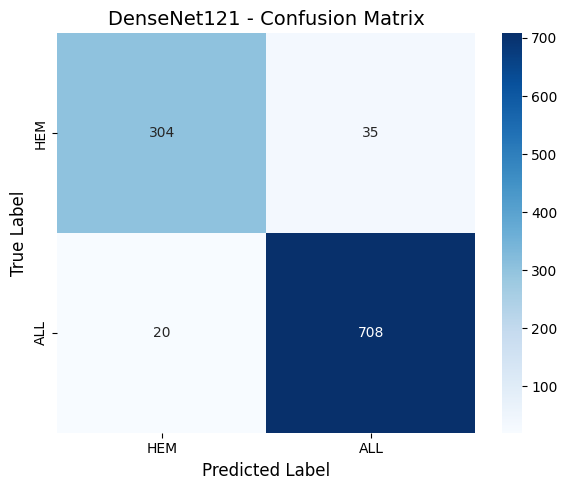


CLASSIFICATION REPORT
              precision    recall  f1-score   support

         HEM     0.9383    0.8968    0.9170       339
         ALL     0.9529    0.9725    0.9626       728

    accuracy                         0.9485      1067
   macro avg     0.9456    0.9346    0.9398      1067
weighted avg     0.9482    0.9485    0.9481      1067


✅ Classification report saved as 'densenet121_classification_report.txt'


In [134]:
# =============================================================================
# CELL 7 : CONFUSION MATRIX & CLASSIFICATION REPORT
# =============================================================================

from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# -----------------------------------------------------------------------------
# CONFUSION MATRIX
# -----------------------------------------------------------------------------

cm = confusion_matrix(all_labels, all_preds)

print("="*80)
print("CONFUSION MATRIX")
print("="*80)
print(cm)

# -----------------------------------------------------------------------------
# PLOT CONFUSION MATRIX
# -----------------------------------------------------------------------------

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["HEM","ALL"],
    yticklabels=["HEM","ALL"]
)

plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("True Label", fontsize=12)
plt.title("DenseNet121 - Confusion Matrix", fontsize=14)

plt.tight_layout()
plt.show()

# -----------------------------------------------------------------------------
# CLASSIFICATION REPORT
# -----------------------------------------------------------------------------

print("\n" + "="*80)
print("CLASSIFICATION REPORT")
print("="*80)

report = classification_report(
    all_labels,
    all_preds,
    target_names=["HEM", "ALL"],
    digits=4
)

print(report)

# -----------------------------------------------------------------------------
# SAVE REPORT
# -----------------------------------------------------------------------------

with open("densenet121_classification_report.txt", "w") as f:
    f.write(report)

print("\n✅ Classification report saved as 'densenet121_classification_report.txt'")

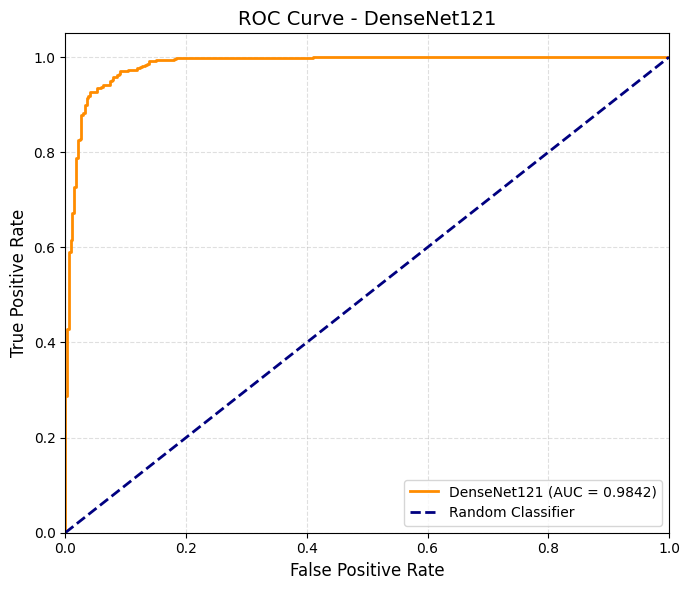

AUC Score : 0.9842


In [135]:
# =============================================================================
# CELL 8 : ROC CURVE
# =============================================================================

from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# -----------------------------------------------------------------------------
# ROC CURVE
# -----------------------------------------------------------------------------

fpr, tpr, thresholds = roc_curve(all_labels, all_probs)

roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7,6))

plt.plot(
    fpr,
    tpr,
    color="darkorange",
    linewidth=2,
    label=f"DenseNet121 (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0,1],
    [0,1],
    linestyle="--",
    color="navy",
    linewidth=2,
    label="Random Classifier"
)

plt.xlim([0.0,1.0])
plt.ylim([0.0,1.05])

plt.xlabel("False Positive Rate", fontsize=12)
plt.ylabel("True Positive Rate", fontsize=12)

plt.title("ROC Curve - DenseNet121", fontsize=14)

plt.legend(loc="lower right")

plt.grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()

plt.show()

print("="*80)
print(f"AUC Score : {roc_auc:.4f}")
print("="*80)

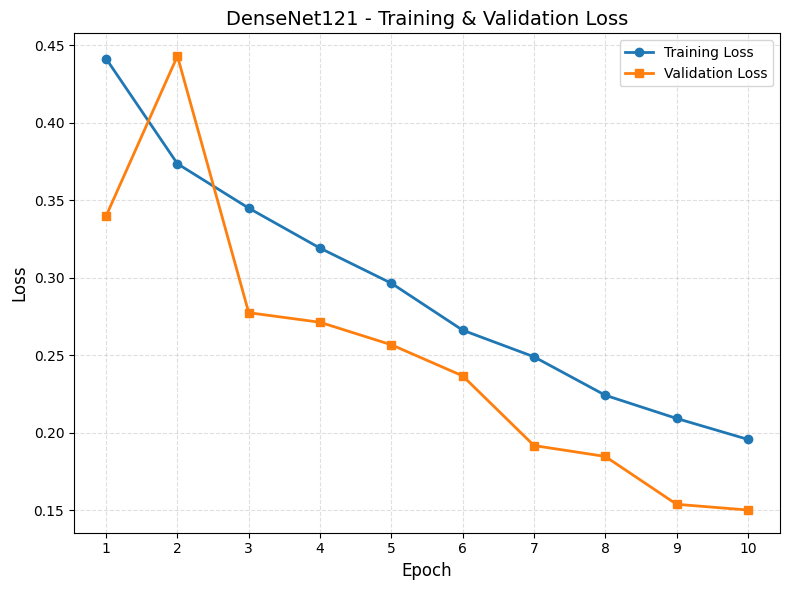

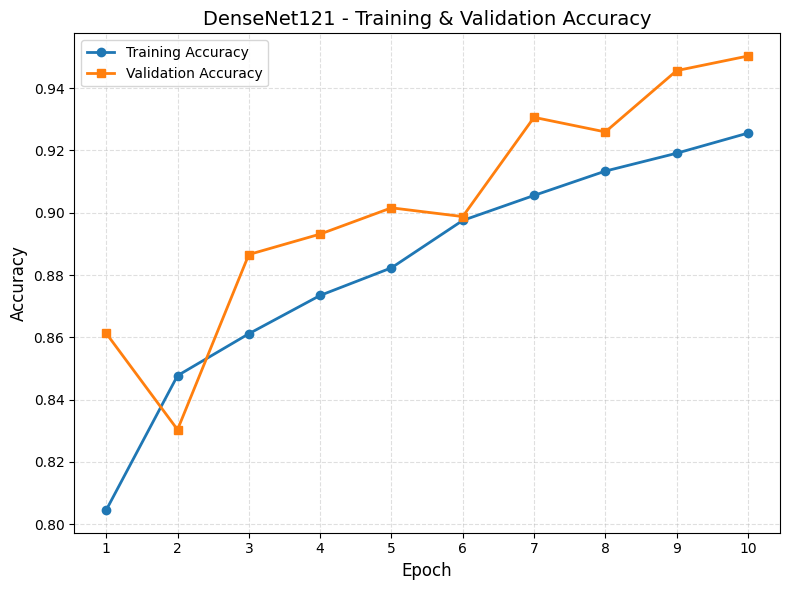

✅ Loss Curve Generated
✅ Accuracy Curve Generated


In [136]:
# =============================================================================
# CELL 9 : TRAINING CURVES
# =============================================================================

import matplotlib.pyplot as plt

epochs = range(1, len(train_loss_history) + 1)

# =============================================================================
# LOSS CURVE
# =============================================================================

plt.figure(figsize=(8,6))

plt.plot(
    epochs,
    train_loss_history,
    marker='o',
    linewidth=2,
    label="Training Loss"
)

plt.plot(
    epochs,
    valid_loss_history,
    marker='s',
    linewidth=2,
    label="Validation Loss"
)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Loss", fontsize=12)
plt.title("DenseNet121 - Training & Validation Loss", fontsize=14)

plt.xticks(epochs)

plt.grid(True, linestyle="--", alpha=0.4)

plt.legend()

plt.tight_layout()

plt.show()


# =============================================================================
# ACCURACY CURVE
# =============================================================================

plt.figure(figsize=(8,6))

plt.plot(
    epochs,
    train_acc_history,
    marker='o',
    linewidth=2,
    label="Training Accuracy"
)

plt.plot(
    epochs,
    valid_acc_history,
    marker='s',
    linewidth=2,
    label="Validation Accuracy"
)

plt.xlabel("Epoch", fontsize=12)
plt.ylabel("Accuracy", fontsize=12)
plt.title("DenseNet121 - Training & Validation Accuracy", fontsize=14)

plt.xticks(epochs)

plt.grid(True, linestyle="--", alpha=0.4)

plt.legend()

plt.tight_layout()

plt.show()

print("="*80)
print("✅ Loss Curve Generated")
print("✅ Accuracy Curve Generated")
print("="*80)

In [137]:
# =============================================================================
# CELL 10 : SAVE FINAL RESULTS
# =============================================================================

import pandas as pd

results = pd.DataFrame({

    "Model": ["DenseNet121"],

    "Accuracy": [accuracy],

    "Precision": [precision],

    "Recall": [recall],

    "F1 Score": [f1],

    "AUC Score": [auc],

    "Best Validation Accuracy": [best_accuracy],

    "Best Epoch": [best_epoch]

})

# Save results
results.to_csv("densenet121_results.csv", index=False)

print("="*80)
print("FINAL RESULTS")
print("="*80)

print(results)

print("\n✅ Results saved as 'densenet121_results.csv'")

print("="*80)

FINAL RESULTS
         Model  Accuracy  Precision    Recall  F1 Score  \
0  DenseNet121  0.948454   0.956698  0.971154  0.963872   

                          AUC Score  Best Validation Accuracy  Best Epoch  
0  <function auc at 0x7bd4464959e0>                  0.950328          10  

✅ Results saved as 'densenet121_results.csv'


In [138]:
# =============================================================================
# NOTEBOOK 3
# CELL 1 : IMPORT LIBRARIES
# =============================================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("="*80)
print("MODEL COMPARISON")
print("="*80)

MODEL COMPARISON


In [139]:
# =============================================================================
# CELL 2 : LOAD RESULTS
# =============================================================================

vit = pd.read_csv("vit_results.csv")

efficientnet = pd.read_csv("efficientnetb3_results.csv")

densenet = pd.read_csv("densenet121_results.csv")

results = pd.concat(
    [vit, efficientnet, densenet],
    ignore_index=True
)

print(results)

                Model  Accuracy  Precision    Recall  F1 Score  \
0  Vision Transformer  0.961575   0.969904  0.973901  0.971899   
1     EfficientNet-B3  0.948454   0.952894  0.972527  0.962610   
2         DenseNet121  0.948454   0.956698  0.971154  0.963872   

                          AUC Score  Best Validation Accuracy  Best Epoch  
0  <function auc at 0x7bd4464959e0>                  0.961575           9  
1  <function auc at 0x7bd4464959e0>                  0.948454           8  
2  <function auc at 0x7bd4464959e0>                  0.950328          10  


In [140]:
# =============================================================================
# CELL 3 : COMPARISON TABLE
# =============================================================================

comparison = results[[
    "Model",
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "AUC Score",
    "Best Validation Accuracy",
    "Best Epoch"
]]

print("="*80)
print("MODEL COMPARISON")
print("="*80)

display(comparison)

MODEL COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,AUC Score,Best Validation Accuracy,Best Epoch
0,Vision Transformer,0.961575,0.969904,0.973901,0.971899,<function auc at 0x7bd4464959e0>,0.961575,9
1,EfficientNet-B3,0.948454,0.952894,0.972527,0.962610,<function auc at 0x7bd4464959e0>,0.948454,8
2,DenseNet121,0.948454,0.956698,0.971154,0.963872,<function auc at 0x7bd4464959e0>,0.950328,10


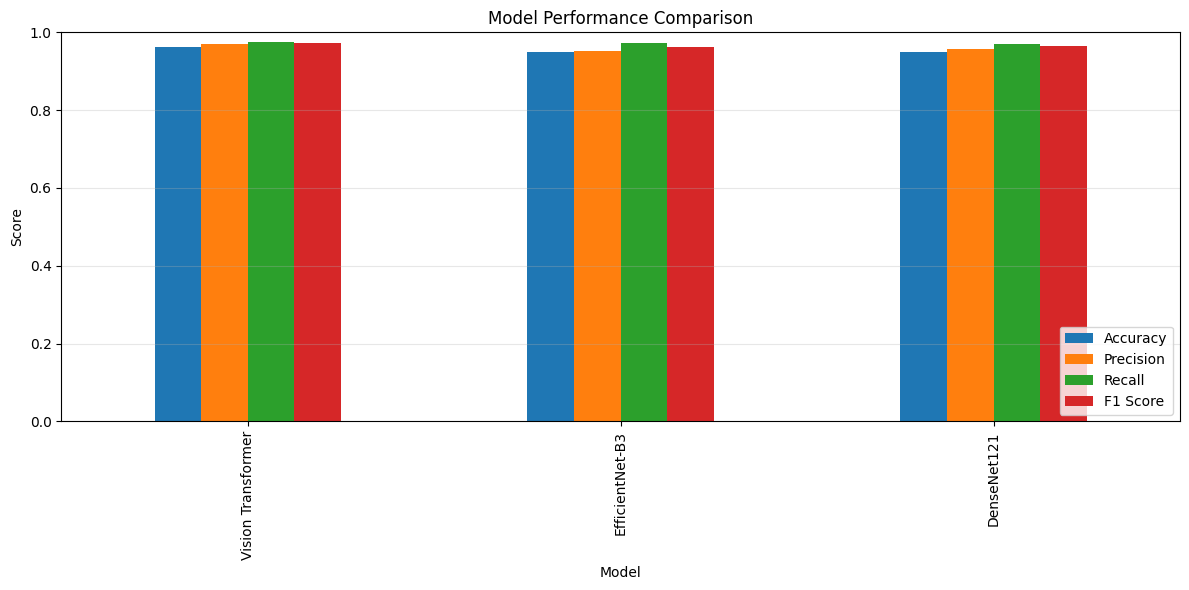

In [141]:
# =============================================================================
# CELL 4 : PERFORMANCE GRAPH
# =============================================================================

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "AUC Score"
]

comparison.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12,6)
)

plt.title("Model Performance Comparison")

plt.ylabel("Score")

plt.ylim(0,1)

plt.grid(axis="y", alpha=0.3)

plt.legend(loc="lower right")

plt.tight_layout()

plt.show()

In [142]:
# =============================================================================
# CELL 5 : BEST MODEL
# =============================================================================

best_model = comparison.sort_values(
    by=[
        "Best Validation Accuracy",
        "F1 Score",
        "AUC Score"
    ],
    ascending=False
).iloc[0]

print("="*80)
print("BEST MODEL")
print("="*80)

print(best_model)

print("\n🏆 Selected Model :", best_model["Model"])

BEST MODEL
Model                                     Vision Transformer
Accuracy                                            0.961575
Precision                                           0.969904
Recall                                              0.973901
F1 Score                                            0.971899
AUC Score                   <function auc at 0x7bd4464959e0>
Best Validation Accuracy                            0.961575
Best Epoch                                                 9
Name: 0, dtype: object

🏆 Selected Model : Vision Transformer


In [143]:
# =============================================================================
# CELL 6 : SAVE BEST MODEL
# =============================================================================

best_model.to_frame().T.to_csv(
    "best_model.csv",
    index=False
)

print("✅ best_model.csv saved.")

✅ best_model.csv saved.


In [144]:
# =============================================================================
# CELL 7 : LOAD BEST MODEL NAME
# =============================================================================

best = pd.read_csv("best_model.csv")

BEST_MODEL = best.loc[0,"Model"]

print("="*80)
print("Best Backbone Selected")
print("="*80)

print(BEST_MODEL)

Best Backbone Selected
Vision Transformer
